### KMeans Result
#### Purpose:
Plot the UMPA coloured by kmeans cluster next to the reference labels.

In [1]:
import yaml
import pandas as pd
import scanpy as sc
from pathlib import Path

In [2]:
ROOT = Path("..")
config = yaml.safe_load(open(ROOT/ "config.yaml"))
adata = sc.read_h5ad(ROOT/config["data_path"])
clusters = pd.read_csv(ROOT/"results"/"clusters_kmeans.csv")

In [3]:
selected_k = config["k_values"][::2]
selected_seeds = config["seeds"][::3]

In [4]:
clusters.columns

Index(['cell_id', 'cluster', 'method', 'parameter', 'seed'], dtype='object')

In [25]:
cols = []

for k in selected_k:
    for s in selected_seeds:    
        run = clusters[(clusters.parameter ==k) & (clusters.seed == s)].set_index("cell_id")
        name = f"k{k}_seed{s}"
        adata.obs[name]= pd.Categorical(run.loc[adata.obs_names, "cluster"].astype(str))
        cols.append(name)

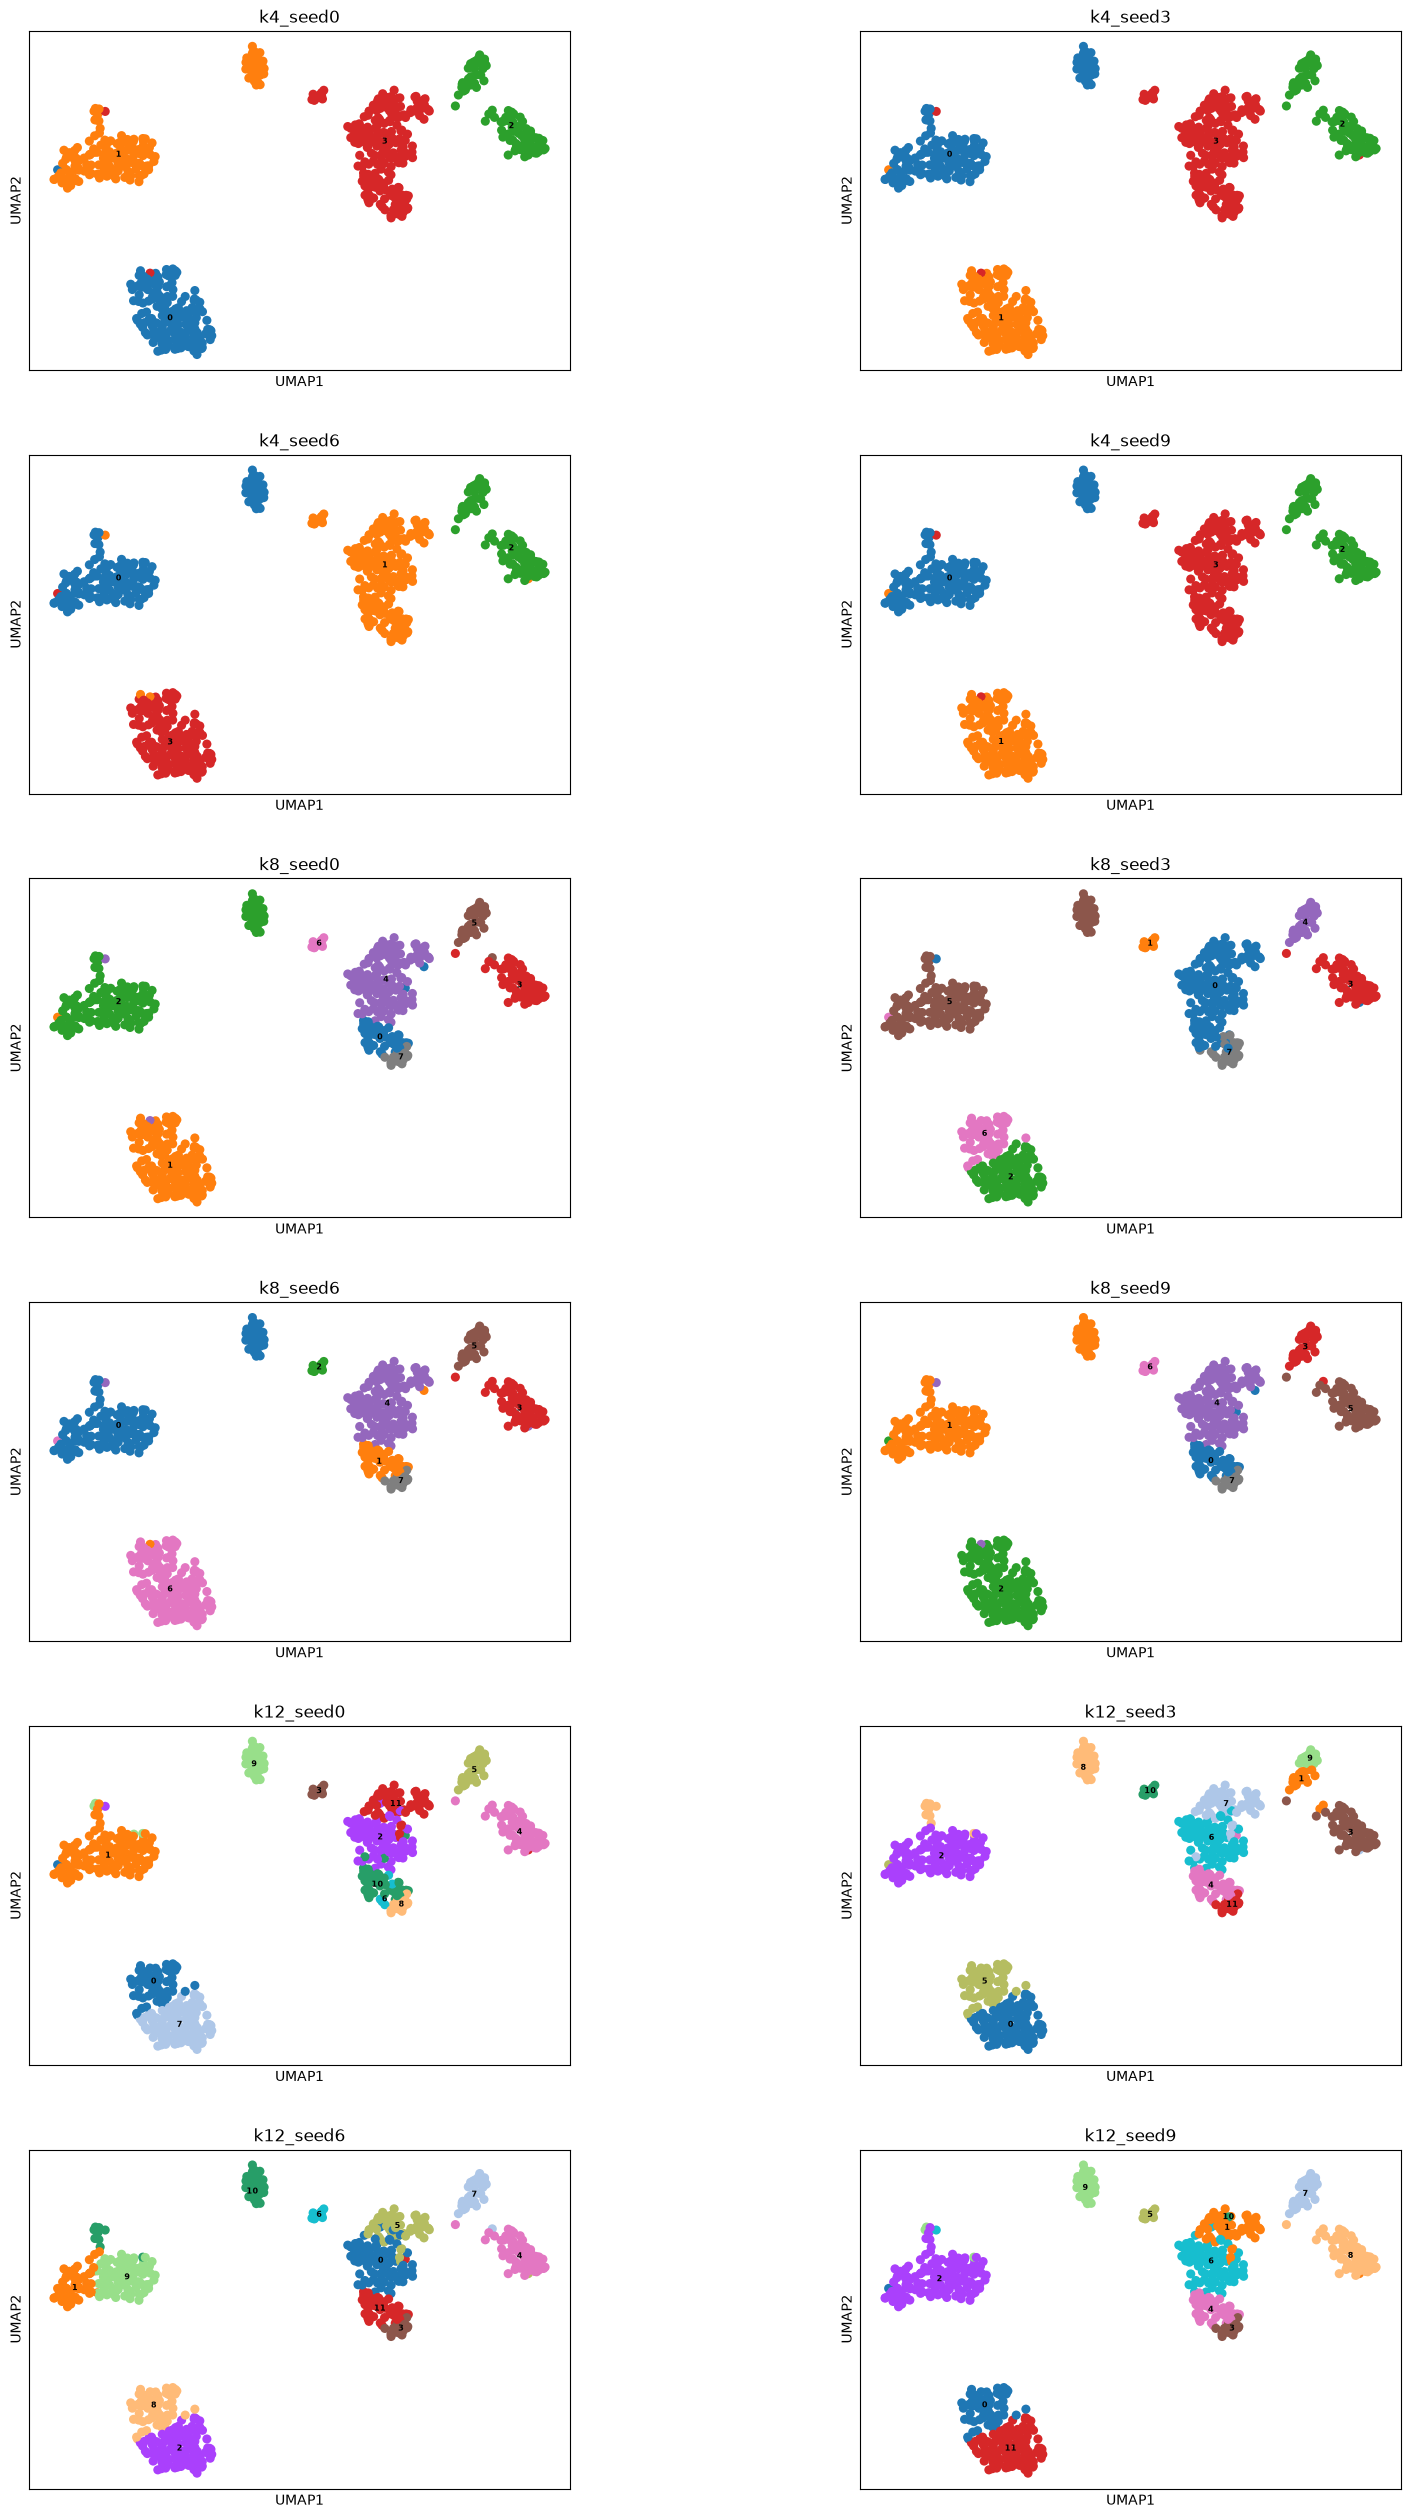

In [26]:
sc.settings.figdir = ROOT/"figures"
sc.pl.umap(adata, color =cols, ncols = (len(selected_seeds)//2), 
           wspace=0.4, legend_loc = "on data", legend_fontsize = 6,
           save = "_kmeans_grid.png")